![Banner](../images/09_13_banner_rs_capstones.png)


# Sea Ice Mapping for Shipping Routes in the St. Lawrence Estuary with RADARSAT Constellation Mission (RCM)

This capstone maps sea ice over the Lower St. Lawrence Estuary, between Baie-Comeau on the north shore and Matane on the south shore, from two dual-polarization (HH + HV) RCM ScanSAR Low Noise GRD scenes acquired on 28 January and 3 February 2026. Every processing step runs in Python with GeoLattice: the RCM-specific steps (reading the product folder, calibration to sigma-nought, thermal noise removal, ground control points and incidence angle) come from `geolattice.rsense.sar.radarsat`, and speckle filtering, geocoding, texture and change detection use the sensor-generic tools in `geolattice.rsense.sar` and `geolattice.rsense.texture`. The RCM products and the AOI are stored in this notebook's `Data/08_remote_sensing/08_11_Capstones/RADARSAT_ICE` directory, and the written workflow behind it is [`sea_ice_mapping_rcm_aoi.md`](https://github.com/zia207/GeoLattice/blob/main/docs/sea_ice_mapping_rcm_aoi.md) in the repository's `docs/` folder.


## Overview

The St. Lawrence is the marine entry to the Great Lakes and the port of Montréal, and it stays open to shipping through the winter. From January to March the estuary carries seasonal ice: new ice and nilas in calm, cold periods, grey and grey-white ice, thin first-year ice, and brash and rafted ice where tides, currents and northwest winds push floes together. Ice moves down the estuary and is often compressed against the south shore, so the same crossing can be easy one week and slow the next. The Baie-Comeau to Matane ferry crosses this AOI, and the main shipping channel runs through it.

Ice services and ship operators rely on SAR because it sees the surface at night and through cloud, and because ice types differ in backscatter and texture. RCM is the Canadian Space Agency's three-satellite C-band mission; its ScanSAR Low Noise mode gives a 350 km swath at 100 m resolution with a lower noise floor than standard ScanSAR, which matters for the weak cross-polarized (HV) return from open water and thin ice. This notebook turns two such scenes into maps a route planner can use: ice versus open water, ice regimes, ice concentration in tenths, change between the two dates, an ice-cost surface and a least-cost route across the estuary.


## Scope and interpretation

The two scenes come from **different satellites (RCM-1 and RCM-3) and different beams (SCLNA and SCLND)**, so they see the AOI at very different incidence angles (about 32 to 38 degrees on 28 January and 50 to 54 degrees on 3 February). HH backscatter falls with incidence angle, so the notebook normalizes HH on both dates to a common 35 degree reference before comparing them, and it checks how far the weak HV signal rises above the instrument noise floor, because at the steeper angle HV is close to that floor. The scenes are **6 days apart**, which is too long to track individual floes in a tidal estuary; the change section therefore describes net change in ice state, not ice drift.

Ice-type classification normally uses training labels from Canadian Ice Service (CIS) ice charts. No CIS charts are bundled here, so the notebook groups ice pixels into **unsupervised ice regimes** with k-means on backscatter and texture features and orders them from smooth and dark to rough and bright. These regimes are a physically reasonable proxy for WMO stages of development, not a validated CIS classification; the last sections explain how to replace them with a supervised Random Forest once chart labels are available. Wind speed is not bundled either, so wind-roughened open water (the main source of error) is flagged for review rather than removed automatically, and only on the date where HV is strong enough to support that test. The route cost scheme is illustrative and should be adjusted to the ice class of the vessel.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings
import xml.etree.ElementTree as ET
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from pyproj import Transformer
from rasterio.features import geometry_mask
from rasterio.transform import Affine
from scipy import ndimage as ndi
from shapely.geometry import LineString, MultiPoint, Point, Polygon, box
from skimage.graph import route_through_array
from sklearn.cluster import KMeans

from geolattice.rsense import sar, texture
from geolattice.rsense.sar import radarsat as rcm

warnings.filterwarnings("ignore", category=RuntimeWarning)          # NaN means over land blocks
warnings.filterwarnings("ignore", message="Dataset has no geotransform")
plt.rcParams.update({"figure.dpi": 110})

DATA_DIR = Path("../../../../Data/08_remote_sensing/08_11_Capstones/RADARSAT_ICE")
if not DATA_DIR.is_dir():
    DATA_DIR = Path("Data/08_remote_sensing/08_11_Capstones/RADARSAT_ICE")
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"RCM data folder not found: {DATA_DIR.resolve()}")
LAND_PATH = DATA_DIR.parent / "hormuz_strait_sentinel1" / "ne_10m_land.geojson"
LAND_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_land.geojson"
OUT_DIR = DATA_DIR.parent.parent / "outputs" / "sea_ice_rcm"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# AOI from aoi.kml ("Segregation area"), read with the standard library
ns = {"k": "http://www.opengis.net/kml/2.2"}
coords_text = ET.parse(DATA_DIR / "aoi.kml").getroot().find(".//k:coordinates", ns).text
aoi_geometry = Polygon([tuple(map(float, c.split(",")[:2])) for c in coords_text.split()])
aoi = gpd.GeoDataFrame({"name": ["Lower St. Lawrence Estuary AOI"]}, geometry=[aoi_geometry], crs="EPSG:4326")
AOI = tuple(float(v) for v in aoi.total_bounds)                       # west, south, east, north
AOI_BUF = (AOI[0] - 0.05, AOI[1] - 0.05, AOI[2] + 0.05, AOI[3] + 0.05)   # about 4-5 km buffer
CRS, RES, REF_DEG = "EPSG:32619", 50.0, 35.0          # UTM 19N, 50 m grid, 35 degree reference

# Each unzipped RCM product folder holds metadata/product.xml; EODMS zips add one extra level
PRODUCTS = sorted({p.parent.parent for p in DATA_DIR.rglob("metadata/product.xml")})
if len(PRODUCTS) < 2:
    raise FileNotFoundError(f"Expected two RCM products under {DATA_DIR}, found {len(PRODUCTS)}")
print("AOI (W, S, E, N):", tuple(round(float(v), 4) for v in AOI))
print("Products:", *[p.name for p in PRODUCTS], sep="\n  ")
print("Outputs:", OUT_DIR)

AOI (W, S, E, N): (-68.3518, 48.915, -67.3295, 49.2468)
Products:
  RCM1_OK3695251_PK4015454_1_SCLNA_20260128_104701_HH_HV_GRD
  RCM3_OK3695270_PK4023614_1_SCLND_20260203_103123_HH_HV_GRD
Outputs: outputs/sea_ice_rcm


## Inspect the scenes and their coverage

`rcm.find_rcm_files` locates the imagery and calibration files of one polarization inside a product folder, and `rcm.read_rcm_metadata` reads the scene facts that should be recorded before processing: satellite, beam mode, pass direction, acquisition time, image size, pixel spacing and the near and far range incidence angles. `rcm.read_rcm_tie_points` reads the geolocation grid in `product.xml`; its convex hull is the scene footprint, which confirms that both acquisitions cover the AOI.


In [2]:
rows, footprints = [], []
for path in PRODUCTS:
    files = rcm.find_rcm_files(path, "HH")
    meta = rcm.read_rcm_metadata(files["product_xml"])
    tie = rcm.read_rcm_tie_points(files["product_xml"])
    footprint = MultiPoint([(g.x, g.y) for g in tie]).convex_hull
    footprints.append(footprint)
    rows.append({
        "product": path.name[:40] + "...",
        "satellite": meta["satellite"], "beam": meta["beam_mode"], "pass": meta["pass"],
        "start (UTC)": str(meta["acquisition_start"])[:19], "lines x samples": f"{meta['lines']} x {meta['samples']}",
        "pixel spacing (m)": meta["pixel_spacing"],
        "incidence (deg)": f"{meta['incidence_near']:.1f} to {meta['incidence_far']:.1f}",
        "AOI covered": f"{footprint.intersection(aoi_geometry).area / aoi_geometry.area:.0%}",
        "noise file": files["noise"].name, "incidence file": files["incidence"].name,
    })
scenes = pd.DataFrame(rows)
order = np.argsort(scenes["start (UTC)"].values)
PRODUCTS = [PRODUCTS[i] for i in order]
footprints = [footprints[i] for i in order]
scenes = scenes.iloc[order].reset_index(drop=True)
DATES = [s[:10] for s in scenes["start (UTC)"]]
scenes

,product,satellite,beam,pass,start (UTC),lines x samples,pixel spacing (m),incidence (deg),AOI covered,noise file,incidence file
0,RCM1_OK3695251_PK4015454_1_SCLNA_2026012...,RCM-1,SCLNA,Descending,2026-01-28T10:47:01,3612 x 8998,40.0,18.8 to 46.1,100%,noiseLevels_HH.xml,incidenceAngles.xml
1,RCM3_OK3695270_PK4023614_1_SCLND_2026020...,RCM-3,SCLND,Descending,2026-02-03T10:31:23,3170 x 9002,40.0,40.4 to 58.6,100%,noiseLevels_HH.xml,incidenceAngles.xml


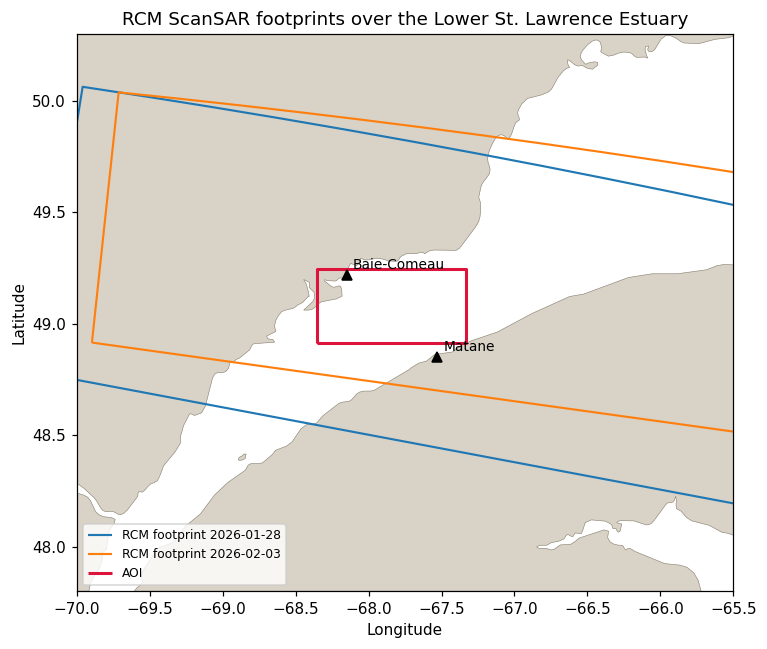

In [3]:
if not LAND_PATH.exists():
    import urllib.request
    LAND_PATH = OUT_DIR / "ne_10m_land.geojson"
    if not LAND_PATH.exists():
        urllib.request.urlretrieve(LAND_URL, LAND_PATH)
view = box(-70.0, 47.8, -65.5, 50.3)
land_all = gpd.read_file(LAND_PATH, bbox=view.bounds).to_crs("EPSG:4326").clip(view)

fig, ax = plt.subplots(figsize=(9, 6))
land_all.plot(ax=ax, color="#d9d3c7", edgecolor="#8c8475", linewidth=0.4)
for fp, d, c in zip(footprints, DATES, ["tab:blue", "tab:orange"]):
    gpd.GeoSeries([fp], crs="EPSG:4326").boundary.plot(ax=ax, color=c, linewidth=1.4, label=f"RCM footprint {d}")
aoi.boundary.plot(ax=ax, color="crimson", linewidth=2, label="AOI")
for name, (lon, lat) in {"Baie-Comeau": (-68.15, 49.22), "Matane": (-67.53, 48.85)}.items():
    ax.plot(lon, lat, "k^", ms=6)
    ax.annotate(name, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.set(xlim=view.bounds[0::2], ylim=view.bounds[1::2], xlabel="Longitude", ylabel="Latitude",
       title="RCM ScanSAR footprints over the Lower St. Lawrence Estuary")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

## Read calibrated, noise-corrected HH and HV over the AOI

`rcm.read_rcm_grd_subset` reads only the image window that covers the buffered AOI, so the full 350 km scenes never have to be loaded. For each polarization it:

1. calibrates digital numbers to sigma-nought with the product's own gain table, `sigma0 = (DN^2 + offset) / gain`, where the gain from `lutSigma_<pol>.xml` varies along range only;
2. subtracts the noise-equivalent sigma-nought (NESZ) from `noiseLevels_<pol>.xml`, stitched across the ScanSAR sub-beams;
3. attaches the ground control points of the window and the ellipsoid incidence angle of every pixel (`incidenceAngles.xml`).

The data stay in radar geometry (rows are azimuth lines, columns are range samples) until Section 4. The noise removal matters most for HV: over calm water and thin ice, HV is close to the instrument noise floor even in Low Noise mode.


In [4]:
subsets = {}
for d, path in zip(DATES, PRODUCTS):
    for pol in ("HH", "HV"):
        s = rcm.read_rcm_grd_subset(path, pol, bounds=AOI_BUF, kind="sigma", noise=True, margin=100)
        subsets[d, pol] = s
        db = sar.to_db(s["data"])
        print(f"{d} {pol}: window (row0, col0, h, w) = {s['window']}, "
              f"median sigma0 {np.nanmedian(db):.1f} dB, incidence {np.nanmin(s['incidence']):.1f} to "
              f"{np.nanmax(s['incidence']):.1f} deg, {len(s['gcps'])} GCPs")

2026-01-28 HH: window (row0, col0, h, w) = (1151, 3029, 1750, 2437), median sigma0 -15.3 dB, incidence 31.2 to 38.5 deg, 35 GCPs


2026-01-28 HV: window (row0, col0, h, w) = (1151, 3029, 1750, 2437), median sigma0 -28.7 dB, incidence 31.2 to 38.5 deg, 35 GCPs


2026-02-03 HH: window (row0, col0, h, w) = (1404, 2490, 1672, 2389), median sigma0 -24.0 dB, incidence 50.0 to 54.6 deg, 35 GCPs


2026-02-03 HV: window (row0, col0, h, w) = (1404, 2490, 1672, 2389), median sigma0 -34.4 dB, incidence 50.0 to 54.6 deg, 35 GCPs


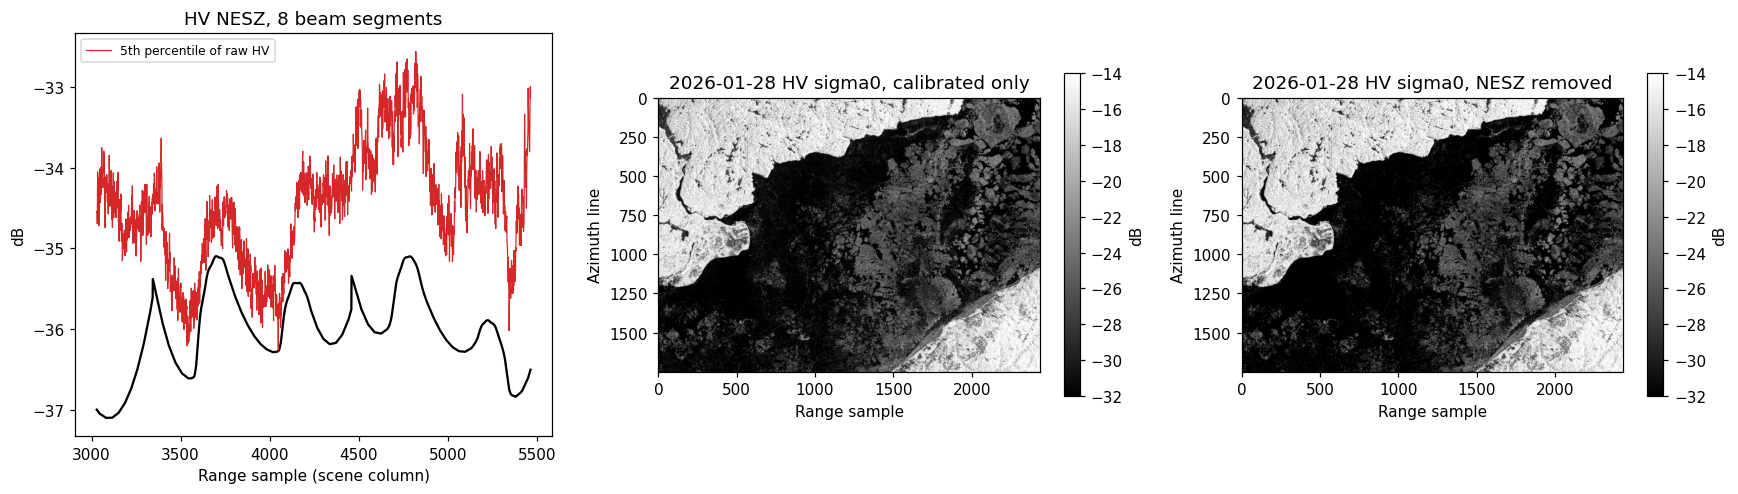

In [5]:
# The HV noise floor across the window, and what removing it does
d0 = DATES[0]
files = rcm.find_rcm_files(PRODUCTS[0], "HV")
row0, col0, h, w = subsets[d0, "HV"]["window"]
segments = rcm.read_rcm_noise_levels(files["noise"], cal_type="Sigma Nought")
nesz_db = rcm.interpolate_rcm_noise(segments, w, col0=col0)
raw_hv = rcm.read_rcm_grd_subset(PRODUCTS[0], "HV", bounds=AOI_BUF, noise=False, incidence=False)["data"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].plot(col0 + np.arange(w), nesz_db, color="k")
axes[0].plot(col0 + np.arange(w), np.nanpercentile(sar.to_db(raw_hv), 5, axis=0), color="tab:red", lw=0.8,
             label="5th percentile of raw HV")
axes[0].set(xlabel="Range sample (scene column)", ylabel="dB", title=f"HV NESZ, {len(segments)} beam segments")
axes[0].legend(fontsize=8)
for ax, img, title in [(axes[1], raw_hv, "HV sigma0, calibrated only"),
                       (axes[2], subsets[d0, "HV"]["data"], "HV sigma0, NESZ removed")]:
    im = ax.imshow(sar.to_db(img), cmap="gray", vmin=-32, vmax=-14)
    ax.set(title=f"{d0} {title}", xlabel="Range sample", ylabel="Azimuth line")
    plt.colorbar(im, ax=ax, shrink=0.8, label="dB")
plt.tight_layout()
plt.show()

## Speckle filtering in radar geometry

Speckle is filtered before geocoding, while neighbouring pixels are still independent looks. The refined Lee filter needs the equivalent number of looks (ENL); RCM ScanSAR differs from the Sentinel-1 default built into the filter, so the ENL is estimated for each image from its most homogeneous 64 x 64 blocks with `sar.ship.estimate_enl`. The unfiltered images are kept for texture (Section 7), because filtering removes the texture that separates rough from smooth ice.


,date,pol,ENL
0,2026-01-28,HH,3.49
1,2026-01-28,HV,3.22
2,2026-02-03,HH,3.09
3,2026-02-03,HV,2.84


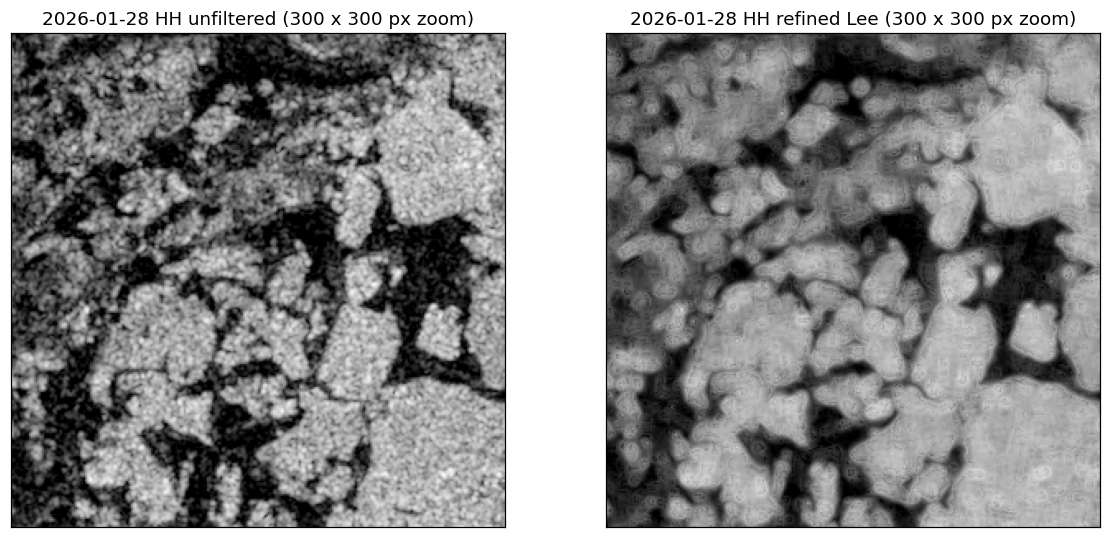

In [6]:
filtered, enl_rows = {}, []
for (d, pol), s in subsets.items():
    enl = sar.ship.estimate_enl(s["data"], np.isfinite(s["data"]), block=64, max_cv_quantile=0.2)
    filtered[d, pol] = s | {"data": sar.refined_lee(s["data"], enl=enl)}
    enl_rows.append({"date": d, "pol": pol, "ENL": round(enl, 2)})
display(pd.DataFrame(enl_rows))

r0, c0 = subsets[d0, "HH"]["data"].shape[0] // 2, subsets[d0, "HH"]["data"].shape[1] // 2
win = (slice(r0 - 150, r0 + 150), slice(c0 - 150, c0 + 150))
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, img, title in [(axes[0], subsets[d0, "HH"]["data"], "HH unfiltered"),
                       (axes[1], filtered[d0, "HH"]["data"], "HH refined Lee")]:
    ax.imshow(sar.to_db(img[win]), cmap="gray", vmin=-26, vmax=-6)
    ax.set(title=f"{d0} {title} (300 x 300 px zoom)", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

## Geocode both dates onto one map grid

`sar.sentinel1.create_stack` is sensor-generic: it geocodes each window with its own ground control points directly onto a common UTM zone 19N grid. The products are sampled at 40 m (100 m resolution); a 50 m grid keeps the full detail of the data while halving the number of pixels. Because both dates land on identical pixels, they are co-registered by construction even though they come from different satellites, beams and orbits. The incidence angle and the HV noise floor (NESZ) are geocoded onto the same grid, the latter so Section 6 can measure how far HV rises above the noise. Geocoding uses the ellipsoid tie points rather than a DEM; over water and sea ice the surface is at sea level, and the coastal mask in Section 5 removes the small displacement on the shoreline.


Common grid: 761 rows x 1505 columns at 50 m, EPSG:32619


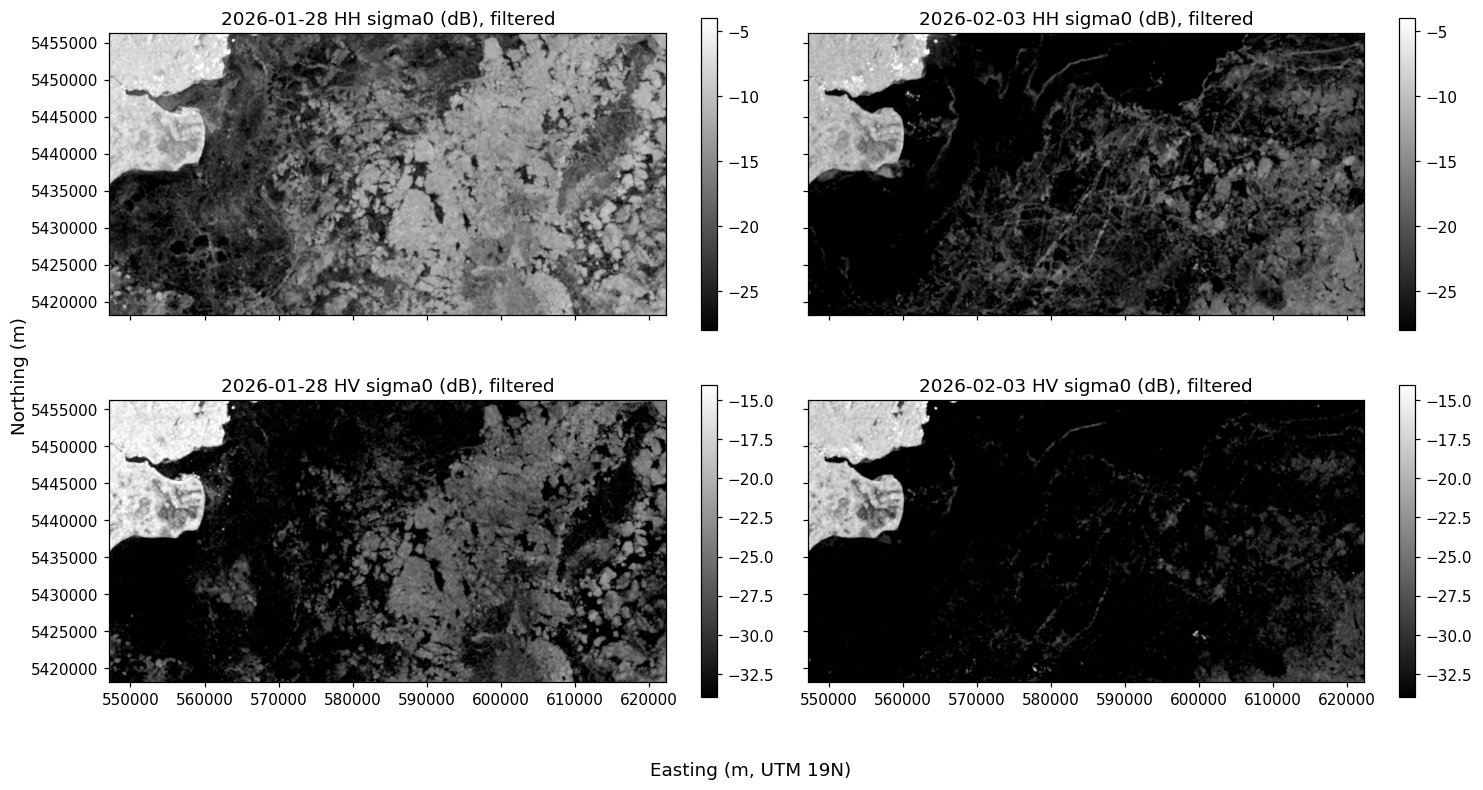

In [7]:
def stack(source, key, name):
    da = sar.sentinel1.create_stack([source[d, key] for d in DATES], DATES, bounds=AOI_BUF,
                                    crs=CRS, resolution=RES, name=name)
    return da.rio.clip_box(*AOI, crs="EPSG:4326")


aux = {}
for d, path in zip(DATES, PRODUCTS):
    s = subsets[d, "HV"]
    _, c0_, h_, w_ = s["window"]
    nesz_d = rcm.interpolate_rcm_noise(rcm.read_rcm_noise_levels(rcm.find_rcm_files(path, "HV")["noise"]), w_, col0=c0_)
    aux[d, "nesz"] = {"data": np.broadcast_to(10 ** (nesz_d / 10), (h_, w_)).astype("float32"), "gcps": s["gcps"]}
    aux[d, "inc"] = {"data": subsets[d, "HH"]["incidence"], "gcps": subsets[d, "HH"]["gcps"]}

hh, hv = stack(filtered, "HH", "sigma0_HH"), stack(filtered, "HV", "sigma0_HV")
hh_raw, hv_raw = stack(subsets, "HH", "sigma0_HH_raw"), stack(subsets, "HV", "sigma0_HV_raw")
inc, nesz = stack(aux, "inc", "incidence"), stack(aux, "nesz", "nesz_HV")
grid = hh.isel(time=0)
transform = grid.rio.transform()
extent = [float(grid.x.min()) - RES / 2, float(grid.x.max()) + RES / 2,
          float(grid.y.min()) - RES / 2, float(grid.y.max()) + RES / 2]
print(f"Common grid: {grid.shape[0]} rows x {grid.shape[1]} columns at {RES:.0f} m, {CRS}")

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True, sharey=True)
for t, d in enumerate(DATES):
    for j, (da, pol, lims) in enumerate([(hh, "HH", (-28, -4)), (hv, "HV", (-34, -14))]):
        im = axes[j, t].imshow(sar.to_db(da.isel(time=t)), cmap="gray", vmin=lims[0], vmax=lims[1], extent=extent)
        axes[j, t].set_title(f"{d} {pol} sigma0 (dB), filtered")
        plt.colorbar(im, ax=axes[j, t], shrink=0.8)
for ax in axes.ravel():
    ax.ticklabel_format(style="plain")
fig.supxlabel("Easting (m, UTM 19N)")
fig.supylabel("Northing (m)")
plt.tight_layout()
plt.show()

## Mask land and the coastal fringe

Natural Earth 1:10m land polygons (already cached for the Hormuz capstone, downloaded otherwise) are rasterized onto the common grid and grown by two pixels (100 m). Natural Earth is generalized, and along the north shore its coastline falls a few hundred metres seaward of the real one, which would leave a strip of bright land to be read as ice. The mask is therefore refined with the SAR itself: land is far brighter than sea ice in HV (about -15 dB against -22 to -30 dB), so pixels within 2 km of the mapped land that are connected to it and brighter than -20 dB in HV on either date are added to the land mask. For production work use GSHHG full resolution or OpenStreetMap land polygons, and still inspect narrow bays and small islands.


Natural Earth land: 7.0% of the grid; after SAR refinement and 100 m buffer: 8.3%
Ocean pixels: 1,050,710 (91.7% of the grid)


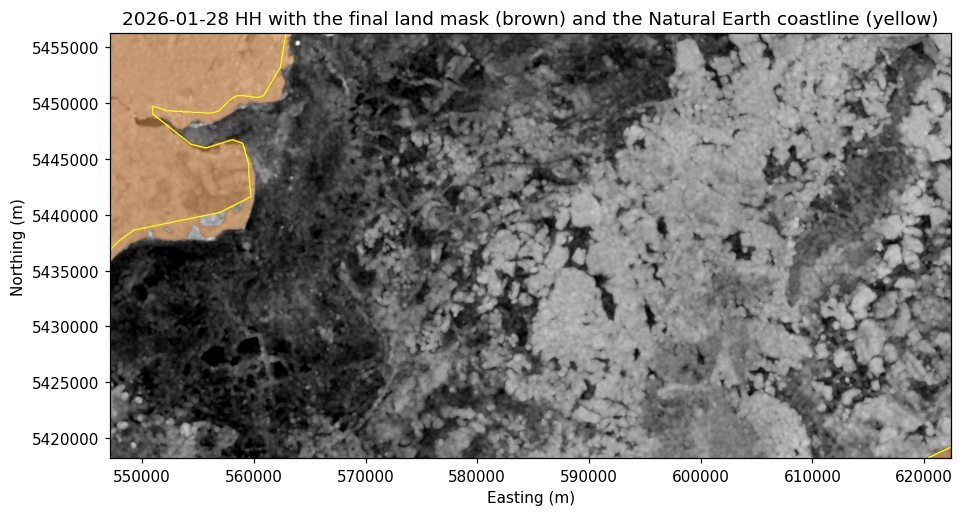

In [8]:
land = land_all.clip(box(*AOI_BUF)).to_crs(CRS)
land_ne = (geometry_mask(land.geometry, out_shape=grid.shape, transform=transform, invert=True)
           if len(land) else np.zeros(grid.shape, bool))
hv_max_db = sar.to_db(hv.max("time")).values
near_land = ndi.distance_transform_edt(~land_ne) * RES <= 2000
bright = ndi.binary_opening(np.nan_to_num(hv_max_db, nan=-99) > -20.0, iterations=1)
candidates = (bright & near_land) | land_ne
lab_, _ = ndi.label(candidates)
land_ids = np.unique(lab_[land_ne])
land_sar = np.isin(lab_, land_ids[land_ids > 0]) if land_ne.any() else land_ne
land_mask = ndi.binary_dilation(land_sar, iterations=2)
ocean = ~land_mask & np.isfinite(hh.values).all(axis=0) & np.isfinite(hv.values).all(axis=0)
print(f"Natural Earth land: {land_ne.mean():.1%} of the grid; after SAR refinement and 100 m buffer: {land_mask.mean():.1%}")
print(f"Ocean pixels: {ocean.sum():,} ({ocean.mean():.1%} of the grid)")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.imshow(sar.to_db(grid), cmap="gray", vmin=-28, vmax=-4, extent=extent)
ax.imshow(np.ma.masked_where(~land_mask, np.ones(grid.shape)), cmap=ListedColormap(["#b5651d"]), alpha=0.55, extent=extent)
ax.contour(land_ne, levels=[0.5], colors="yellow", linewidths=0.8, extent=extent, origin="upper")
ax.set(title=f"{DATES[0]} HH with the final land mask (brown) and the Natural Earth coastline (yellow)",
       xlabel="Easting (m)", ylabel="Northing (m)")
ax.ticklabel_format(style="plain")
plt.tight_layout()
plt.show()

## Convert to dB, check the HV noise floor, and normalize the incidence angle

**HV signal-to-noise.** Cross-polarized backscatter from open water and thin ice is weak, and it weakens further at steep incidence. Subtracting the noise floor removes the bias, but where the true signal is below the NESZ what remains is mostly noise. For each date the notebook compares noise-corrected HV with the geocoded NESZ over the ocean; HV is used as an ice indicator only on dates where the median margin is at least 3 dB.

**Incidence angle.** HH backscatter decreases with incidence angle, and these two beams see the AOI at very different angles (Section 2), so the dates are not comparable as they stand. A linear model `sigma0_norm(dB) = sigma0(dB) - k (theta - 35)` brings HH to a 35 degree reference. The slope `k` must come from one surface type, so a first ice mask from a per-date Otsu threshold on HH selects ice pixels and `rcm.fit_incidence_slope` fits `k` within each date. Within one scene the AOI spans only about 4 to 6 degrees, and ice types vary across it, so the fit is often weakly constrained: a fitted slope is used only if it lies between -0.40 and -0.05 dB per degree with R² of at least 0.2, otherwise the published value for first-year ice in HH, -0.22 dB per degree, is used. HV is not normalized: its incidence dependence over ice is small, and on a noise-limited date a fitted HV slope would describe the noise, not the ice.


In [9]:
hh_db, hv_db, nesz_db = sar.to_db(hh), sar.to_db(hv), sar.to_db(nesz)
hv_snr, HV_OK, snr_rows = [], [], []
for t, d in enumerate(DATES):
    snr = (hv_db.isel(time=t) - nesz_db.isel(time=t)).values
    hv_snr.append(snr)
    med = float(np.nanmedian(snr[ocean]))
    HV_OK.append(med >= 3.0)
    snr_rows.append({"date": d, "median HV (dB)": round(float(np.nanmedian(hv_db.isel(time=t).values[ocean])), 1),
                     "median NESZ (dB)": round(float(np.nanmedian(nesz_db.isel(time=t).values[ocean])), 1),
                     "median HV - NESZ (dB)": round(med, 1),
                     "ocean px with HV >= NESZ + 3 dB": f"{(snr[ocean] >= 3).mean():.0%}",
                     "HV used": "yes" if med >= 3.0 else "no (noise-limited)"})
display(pd.DataFrame(snr_rows))

first_ice = []
for t in range(len(DATES)):
    v = hh_db.isel(time=t).values
    first_ice.append((v > sar.threshold(v[ocean & np.isfinite(v)], method="otsu")) & ocean)

DEFAULT_SLOPE, fits = -0.22, []
for t, d in enumerate(DATES):
    try:
        f = rcm.fit_incidence_slope(hh_db.isel(time=t), inc.isel(time=t), mask=first_ice[t], min_count=5000)
    except ValueError as err:
        f = {"slope": np.nan, "intercept": np.nan, "r2": np.nan, "n": 0}
    theta_ocean = inc.isel(time=t).values[ocean]
    f["incidence range (deg)"] = f"{np.nanmin(theta_ocean):.1f} to {np.nanmax(theta_ocean):.1f}"
    f["accepted"] = bool(np.isfinite(f["slope"]) and -0.40 <= f["slope"] <= -0.05 and f["r2"] >= 0.2)
    fits.append({"date": d, **f})
fits = pd.DataFrame(fits)
K_HH = float(fits.loc[fits.accepted, "slope"].mean()) if fits.accepted.any() else DEFAULT_SLOPE
hh_n = rcm.normalize_incidence(hh_db, inc, K_HH, ref_deg=REF_DEG)
print(f"HH incidence slope used: {K_HH:.3f} dB/deg "
      f"({'mean of accepted fits' if fits.accepted.any() else 'published first-year-ice value; no fit accepted'})")
for t, d in enumerate(DATES):
    shift = -K_HH * (np.nanmean(inc.isel(time=t).values[ocean]) - REF_DEG)
    print(f"  {d}: mean adjustment {shift:+.1f} dB")
fits.round(3)

,date,median HV (dB),median NESZ (dB),median HV - NESZ (dB),ocean px with HV >= NESZ + 3 dB,HV used
0,2026-01-28,-32.0,-35.9,3.8,56%,yes
1,2026-02-03,-36.1,-36.2,0.1,18%,no (noise-limited)


HH incidence slope used: -0.220 dB/deg (published first-year-ice value; no fit accepted)
  2026-01-28: mean adjustment -0.1 dB
  2026-02-03: mean adjustment +3.8 dB


,date,slope,intercept,r2,n,incidence range (deg),accepted
0,2026-01-28,-0.495,2.162,0.065,536115,31.9 to 37.7,False
1,2026-02-03,-1.271,43.408,0.140,561086,50.5 to 54.1,False


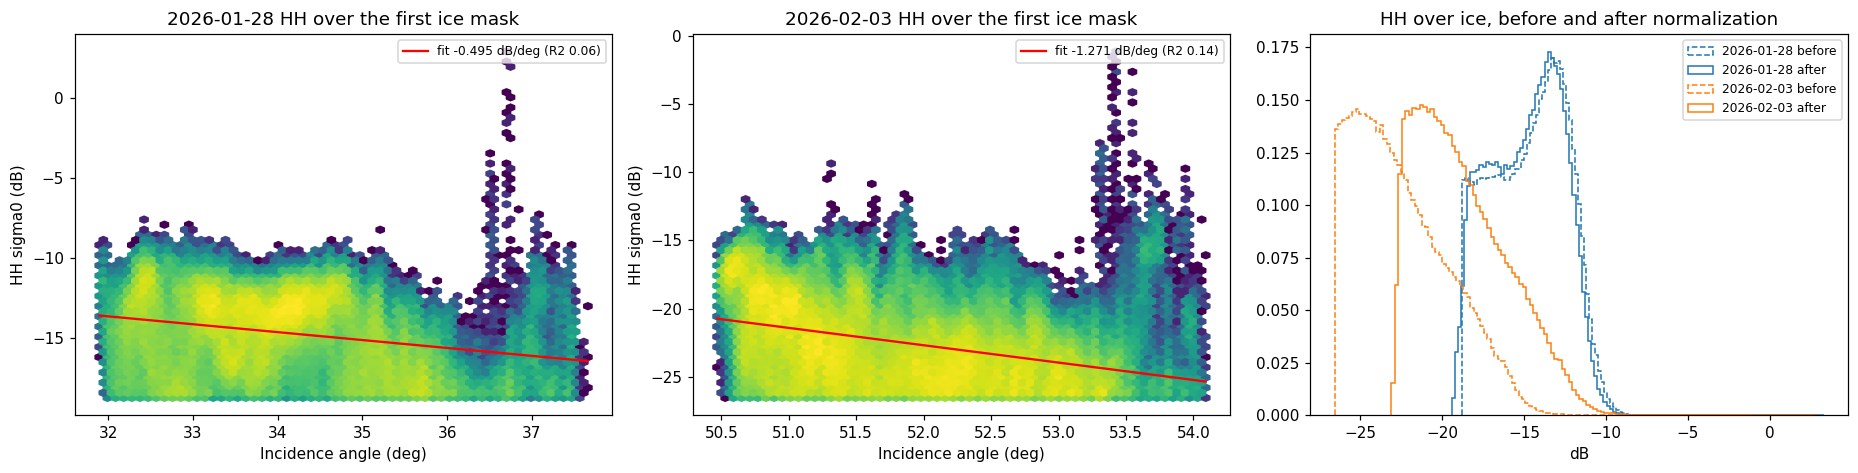

In [10]:
fig, axes = plt.subplots(1, len(DATES) + 1, figsize=(17, 4.4))
for t, (d, ax) in enumerate(zip(DATES, axes)):
    m = first_ice[t]
    theta, s_db = inc.isel(time=t).values[m], hh_db.isel(time=t).values[m]
    keep = np.isfinite(theta) & np.isfinite(s_db)
    ax.hexbin(theta[keep], s_db[keep], gridsize=60, bins="log", cmap="viridis", mincnt=1)
    tt = np.linspace(theta[keep].min(), theta[keep].max(), 10)
    f = fits.iloc[t]
    if np.isfinite(f.slope):
        ax.plot(tt, f.intercept + f.slope * tt, "r-", label=f"fit {f.slope:.3f} dB/deg (R2 {f.r2:.2f})")
    ax.set(title=f"{d} HH over the first ice mask", xlabel="Incidence angle (deg)", ylabel="HH sigma0 (dB)")
    ax.legend(fontsize=8)
for t, d in enumerate(DATES):
    for da, ls, lab in [(hh_db, "--", "before"), (hh_n, "-", "after")]:
        v = da.isel(time=t).values[first_ice[t]]
        axes[-1].hist(v[np.isfinite(v)], bins=120, histtype="step", ls=ls, density=True,
                      color=["tab:blue", "tab:orange"][t], label=f"{d} {lab}")
axes[-1].set(title="HH over ice, before and after normalization", xlabel="dB")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Backscatter and texture features

Each date gets a feature stack on the common grid. Backscatter alone separates ice from calm water but not ice types from each other, so texture is added from the **unfiltered** images: grey-level co-occurrence (GLCM) contrast and homogeneity from HH, which respond to ridges, rafting and floe edges versus smooth new ice, GLCM entropy from HV, and the local standard deviation of HH. Distance to the coast helps separate landfast ice from drifting ice.

| Feature | Meaning |
|---|---|
| `HH_dB` | HH normalized to 35 degrees |
| `HV_dB` | noise-corrected HV (not normalized) |
| `ratio_dB` | HH minus HV (co-/cross-pol ratio) |
| `GLCM_contrast_HH`, `GLCM_homogeneity_HH` | roughness versus smoothness |
| `GLCM_entropy_HV` | structure in the cross-pol channel |
| `local_std_HH` | local variability (7 x 7 window) |
| `dist_coast_km` | distance to the land mask |

`texture.glcm_texture` computes the GLCM in an 11 x 11 window every third pixel (32 grey levels, four directions) and resamples back to full resolution. It is the slowest step in the notebook, typically one to two minutes per date.


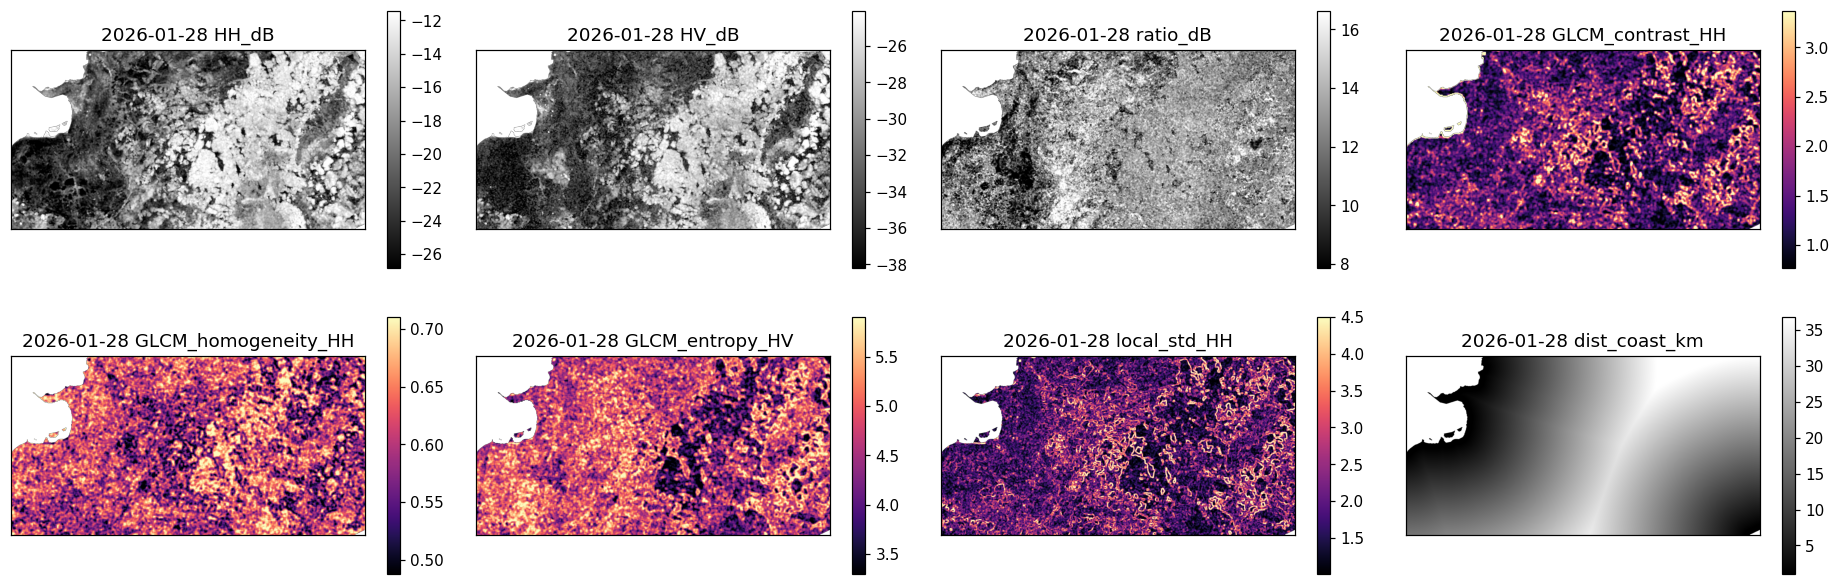

In [11]:
FEATURES = ["HH_dB", "HV_dB", "ratio_dB", "GLCM_contrast_HH", "GLCM_homogeneity_HH",
            "GLCM_entropy_HV", "local_std_HH", "dist_coast_km"]
dist_coast = ndi.distance_transform_edt(~land_mask) * RES / 1000.0
xr_ocean = grid.copy(data=ocean)


def feature_stack(t):
    hh_t, hv_t = hh_n.isel(time=t).values, hv_db.isel(time=t).values
    hh_tex = sar.to_db(hh_raw.isel(time=t)).where(xr_ocean)
    hv_tex = sar.to_db(hv_raw.isel(time=t)).where(xr_ocean)
    g_hh = texture.glcm_texture(hh_tex, size=11, step=3, levels=32, props=("contrast", "homogeneity"))
    g_hv = texture.glcm_texture(hv_tex, size=11, step=3, levels=32, props=("entropy",))
    std_hh = texture.first_order_stats(hh_tex, size=7, stats=("std",))["std"]
    layers = [hh_t, hv_t, hh_t - hv_t, g_hh["contrast"], g_hh["homogeneity"], g_hv["entropy"], std_hh, dist_coast]
    out = np.stack([np.asarray(getattr(a, "values", a), "float32") for a in layers])
    out[:, ~ocean] = np.nan
    return out


stacks = [feature_stack(t) for t in range(len(DATES))]

fig, axes = plt.subplots(2, 4, figsize=(17, 6.2))
for ax, name, layer in zip(axes.ravel(), FEATURES, stacks[0]):
    lo, hi = np.nanpercentile(layer, [2, 98])
    im = ax.imshow(layer, cmap="magma" if "GLCM" in name or "std" in name else "gray", vmin=lo, vmax=hi)
    ax.set(title=f"{DATES[0]} {name}", xticks=[], yticks=[])
    plt.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()

## Separate ice from open water

Normalized HH separates ice from open water on both dates, including the steep-incidence scene where calm water is very dark. Because the two scenes differ in incidence, noise floor and conditions, the split uses an Otsu threshold **per date** rather than one threshold for both, followed by a small morphological opening that removes isolated noise pixels. HV is used as supporting evidence only where Section 6 found it above the noise floor:

- the agreement between the HH ice mask and an HV Otsu ice mask is reported as a consistency check;
- **wind-roughened open water**, the main source of error, can be bright in HH but stays dark in HV and smooth in texture. Pixels that the HH mask calls ice but that are dark in HV, have low GLCM contrast and lie at least 3 dB above the HV noise floor are flagged for review rather than removed, because no wind data are bundled. Where ERA5 10 m wind exceeds about 8 m/s at acquisition time, treat flagged pixels as open water.

On a noise-limited date neither check is possible, which the output states.


,date,"HH threshold (dB, normalized)",ice fraction,HV threshold (dB),HH/HV agreement,flagged rough water
0,2026-01-28,-18.8,49.9%,-31.0,88.8%,2.6%
1,2026-02-03,-22.7,52.2%,n/a,n/a (HV noise-limited),not assessed


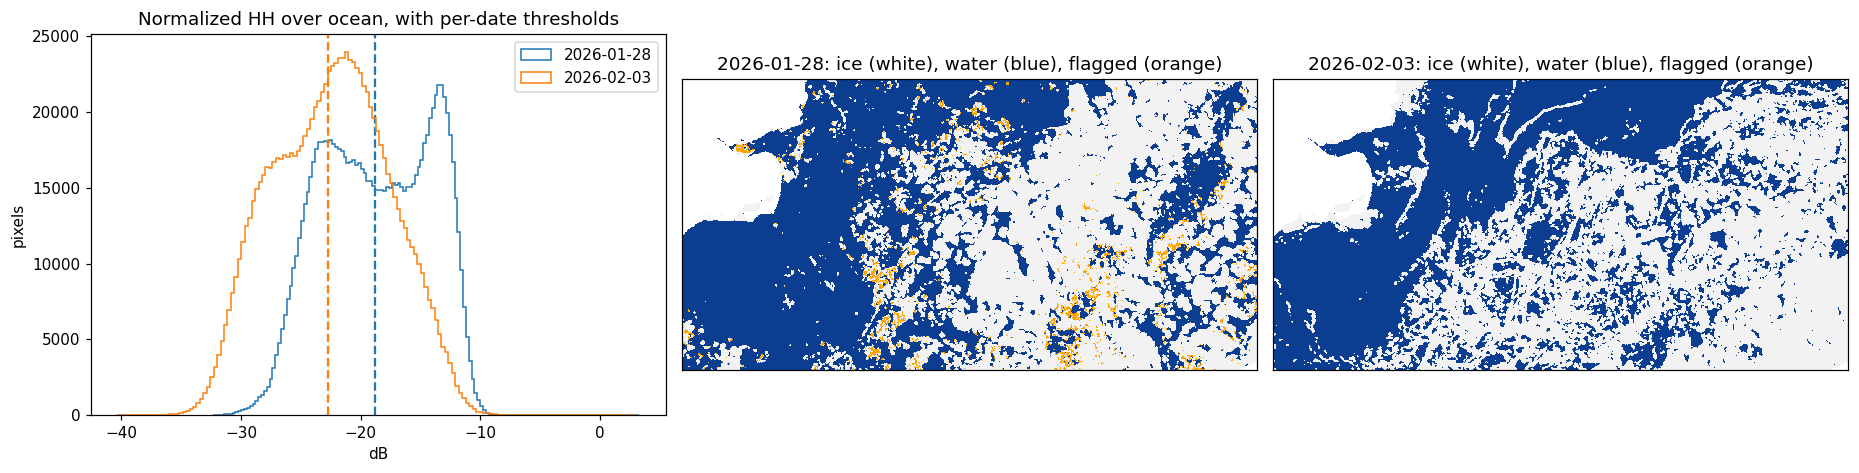

In [12]:
ice, rough_water, T_HH, agree_rows = [], [], [], []
for t, d in enumerate(DATES):
    v = hh_n.isel(time=t).values
    thr = sar.threshold(v[ocean & np.isfinite(v)], method="otsu")
    m = ndi.binary_opening((v > thr) & ocean, iterations=1) & ocean
    flag = np.zeros(grid.shape, bool)
    row = {"date": d, "HH threshold (dB, normalized)": round(thr, 1), "ice fraction": f"{m[ocean].mean():.1%}"}
    if HV_OK[t]:
        hvv = hv_db.isel(time=t).values
        thr_hv = sar.threshold(hvv[ocean & np.isfinite(hvv)], method="otsu")
        ice_hv = (hvv > thr_hv) & ocean
        contrast = stacks[t][FEATURES.index("GLCM_contrast_HH")]
        flag = m & ~ice_hv & (hv_snr[t] >= 3) & (contrast < np.nanmedian(contrast[m]))
        row.update({"HV threshold (dB)": round(thr_hv, 1),
                    "HH/HV agreement": f"{((m == ice_hv)[ocean]).mean():.1%}",
                    "flagged rough water": f"{flag[ocean].mean():.1%}"})
    else:
        row.update({"HV threshold (dB)": "n/a", "HH/HV agreement": "n/a (HV noise-limited)",
                    "flagged rough water": "not assessed"})
    ice.append(m)
    rough_water.append(flag)
    T_HH.append(thr)
    agree_rows.append(row)
display(pd.DataFrame(agree_rows))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for t, d in enumerate(DATES):
    v = hh_n.isel(time=t).values[ocean]
    axes[0].hist(v[np.isfinite(v)], bins=150, histtype="step", color=["tab:blue", "tab:orange"][t], label=d)
    axes[0].axvline(T_HH[t], color=["tab:blue", "tab:orange"][t], ls="--")
axes[0].set(title="Normalized HH over ocean, with per-date thresholds", xlabel="dB", ylabel="pixels")
axes[0].legend()
for t, (d, ax) in enumerate(zip(DATES, axes[1:])):
    show = np.where(ocean, ice[t].astype(float), np.nan)
    ax.imshow(show, cmap=ListedColormap(["#0b3d91", "#f2f2f2"]), extent=extent, interpolation="nearest")
    ax.imshow(np.ma.masked_where(~rough_water[t], np.ones(grid.shape)), cmap=ListedColormap(["orange"]),
              extent=extent, interpolation="nearest")
    ax.set(title=f"{d}: ice (white), water (blue), flagged (orange)", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

## Ice regimes and landfast ice

Ice pixels from both dates are pooled and grouped into four regimes with k-means on standardized normalized HH and HH texture (GLCM contrast, GLCM homogeneity and local standard deviation). HV and the co-/cross-pol ratio are left out because HV is noise-limited on one of the two dates, and distance to coast is left out so the regimes describe the ice, not its location. Pooling keeps the regime definitions identical on both dates. Each feature is clipped at its 1st and 99th percentiles before clustering, so a few extreme texture values along floe and image edges cannot claim a cluster of their own. The cluster with the strongest texture (high GLCM contrast and local variability, low homogeneity) is named rough or deformed ice; the other three are ordered by mean normalized HH from dark to bright. The names follow the stages of development each regime most resembles:

| ID | Regime | Typical appearance | Closest WMO stages |
|---|---|---|---|
| 0 | Open water | dark in normalized HH | ice-free |
| 1 | Smooth dark ice | lowest HH among ice, smooth | new ice, nilas |
| 2 | Grey ice | moderate HH | grey, grey-white |
| 3 | Thin first-year ice | brightest HH among smoother ice, large floes | thin first-year |
| 4 | Rough or deformed ice | strongest texture | brash, rafted, ridged |
| 5 | Landfast candidate | ice joined to shore, stable between dates | fast ice |

A pixel becomes a landfast candidate when it is ice on both dates, belongs to an ice body that touches the coast, lies within 3 km of land, and its normalized HH changed by less than 1.5 dB. These names are interpretations of unsupervised clusters; Section 15 explains how to train a supervised classifier from CIS charts instead.


In [13]:
CLASS_NAMES = ["Open water", "Smooth dark ice", "Grey ice", "Thin first-year ice", "Rough/deformed ice",
               "Landfast candidate"]
CLASS_COLORS = ["#0b3d91", "#c6dbef", "#9e9ac8", "#f0f0f0", "#fd8d3c", "#31a354"]
cmap_cls = ListedColormap(CLASS_COLORS)
norm_cls = BoundaryNorm(np.arange(-0.5, 6.5), cmap_cls.N)
REGIME_FEATURES = ["HH_dB", "GLCM_contrast_HH", "GLCM_homogeneity_HH", "local_std_HH"]
use = [FEATURES.index(n) for n in REGIME_FEATURES]

X_all = np.concatenate([stacks[t][use][:, ice[t]].T for t in range(len(DATES))])
valid = np.isfinite(X_all).all(axis=1)
lo_clip, hi_clip = np.percentile(X_all[valid], [1, 99], axis=0)
mu = np.clip(X_all[valid], lo_clip, hi_clip).mean(axis=0)
sd = np.clip(X_all[valid], lo_clip, hi_clip).std(axis=0)


def standardize(X):
    return (np.clip(X, lo_clip, hi_clip) - mu) / sd


rng = np.random.default_rng(42)
sample = rng.choice(np.flatnonzero(valid), size=min(200_000, int(valid.sum())), replace=False)
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(standardize(X_all[sample]))
z = km.cluster_centers_                                           # standardized cluster centres
roughness = z[:, 1] + z[:, 3] - z[:, 2]                           # contrast + local std - homogeneity
rough_cluster = int(np.argmax(roughness))
others = sorted((c for c in range(4) if c != rough_cluster), key=lambda c: z[c, 0])   # dark to bright HH
cluster_to_class = {c: k + 1 for k, c in enumerate(others)} | {rough_cluster: 4}

ice_class = []
for t in range(len(DATES)):
    cls = np.full(grid.shape, 255, np.uint8)
    cls[ocean] = 0
    X = stacks[t][use][:, ice[t]].T
    ok = np.isfinite(X).all(axis=1)
    lab = np.full(len(X), 3, np.uint8)
    lab[ok] = [cluster_to_class[c] for c in km.predict(standardize(X[ok]))]
    cls[ice[t]] = lab
    ice_class.append(cls)

# Landfast candidates: ice on both dates, attached to the coast, within 3 km, stable HH
dhh = (hh_n.isel(time=1) - hh_n.isel(time=0)).values
both = ice[0] & ice[1]
labels, n = ndi.label(both)
coastal = np.unique(labels[ndi.binary_dilation(land_mask, iterations=2) & both])
attached = np.isin(labels, coastal[coastal > 0])
landfast = attached & (dist_coast <= 3.0) & (np.abs(dhh) < 1.5)
for cls in ice_class:
    cls[landfast] = 5

centers = pd.DataFrame(km.cluster_centers_ * sd + mu, columns=REGIME_FEATURES)
centers["roughness score"] = roughness
centers.index = [CLASS_NAMES[cluster_to_class[c]] for c in range(4)]
centers.loc[CLASS_NAMES[1:5]].round(2)

,HH_dB,GLCM_contrast_HH,GLCM_homogeneity_HH,local_std_HH,roughness score
Smooth dark ice,-19.99,1.15,0.65,2.31,-0.86
Grey ice,-15.29,1.73,0.59,2.23,0.98
Thin first-year ice,-14.19,0.95,0.68,1.53,-2.47
Rough/deformed ice,-16.74,2.45,0.54,3.77,4.55


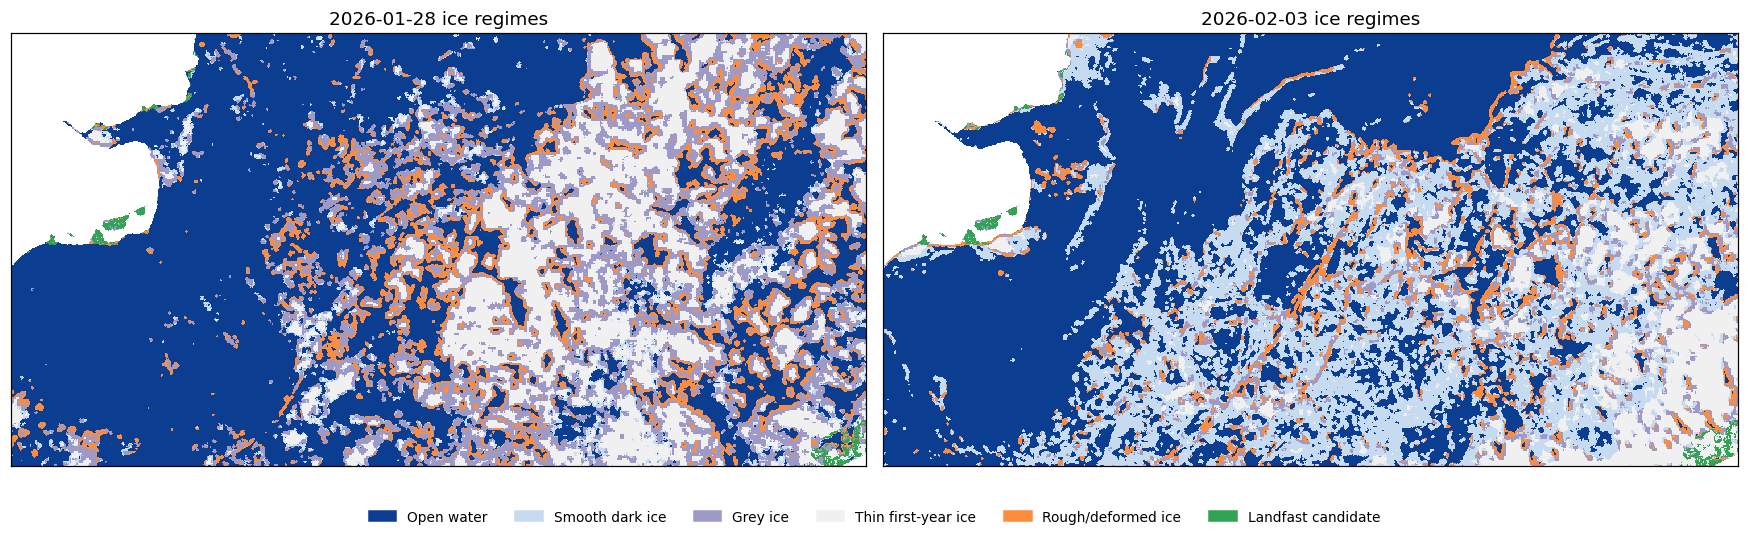

,2026-01-28,2026-02-03
area (km2),,
Open water,1314.7,1255.9
Smooth dark ice,72.4,810.9
Grey ice,507.8,144.2
Thin first-year ice,464.2,250.7
Rough/deformed ice,257.3,154.8
Landfast candidate,10.3,10.3


In [14]:
fig, axes = plt.subplots(1, len(DATES), figsize=(16, 4.8))
for t, (d, ax) in enumerate(zip(DATES, axes)):
    show = np.where(ice_class[t] == 255, np.nan, ice_class[t]).astype(float)
    ax.imshow(show, cmap=cmap_cls, norm=norm_cls, extent=extent, interpolation="nearest")
    ax.set(title=f"{d} ice regimes", xticks=[], yticks=[])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=6, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

area_km2 = (RES / 1000) ** 2
summary = pd.DataFrame({d: [(ice_class[t] == k).sum() * area_km2 for k in range(6)] for t, d in enumerate(DATES)},
                       index=CLASS_NAMES).round(1)
summary.index.name = "area (km2)"
summary

## Ice concentration

Ice concentration is the fraction of ice-covered ocean pixels in a cell, reported in **tenths** (0 to 10) to match the CIS egg code. A 1 km grid (20 x 20 pixels) feeds the route analysis and a 5 km grid matches the scale of CIS chart comparison. Cells that are entirely land or coast are left empty.


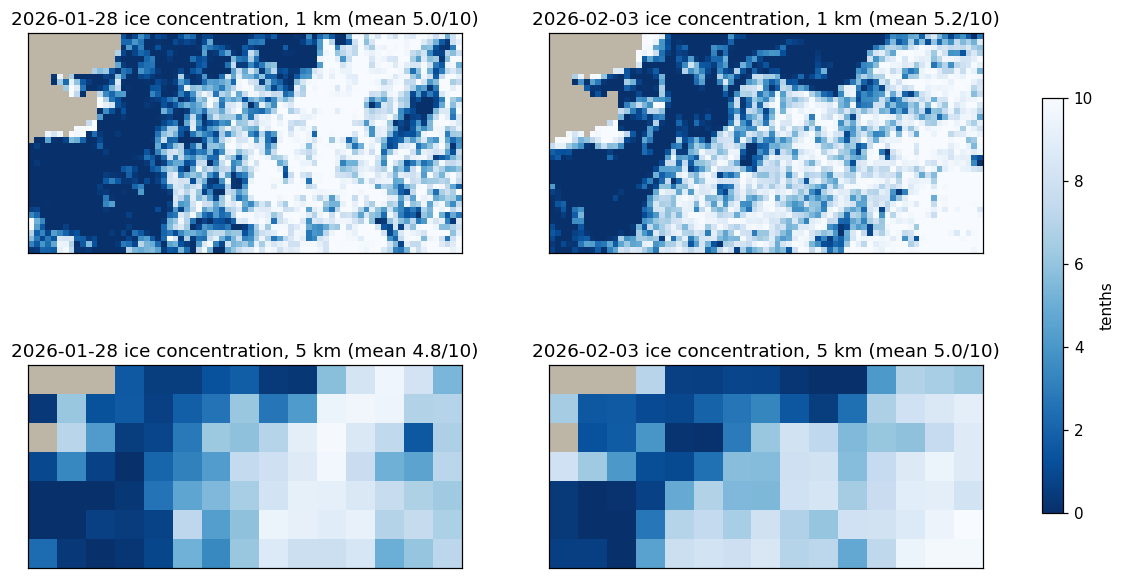

In [15]:
def ice_concentration(ice_binary, factor):
    # ice_binary: 1 = ice, 0 = water, NaN = land; returns tenths on a coarser grid
    h, w = ice_binary.shape
    blocks = ice_binary[: h // factor * factor, : w // factor * factor]
    return np.nanmean(blocks.reshape(h // factor, factor, w // factor, factor), axis=(1, 3)) * 10


F1, F5 = int(1000 / RES), int(5000 / RES)
CT_CMAP = plt.get_cmap("Blues_r").copy()
CT_CMAP.set_bad("#bdb5a6")                       # land and coast in grey, not white (10/10 ice)
ct1 = [ice_concentration(np.where(ocean, ice[t].astype("float32"), np.nan), F1) for t in range(len(DATES))]
ct5 = [ice_concentration(np.where(ocean, ice[t].astype("float32"), np.nan), F5) for t in range(len(DATES))]

fig, axes = plt.subplots(2, len(DATES), figsize=(14, 7))
for t, d in enumerate(DATES):
    for j, (ct, label) in enumerate([(ct1[t], "1 km"), (ct5[t], "5 km")]):
        im = axes[j, t].imshow(ct, cmap=CT_CMAP, vmin=0, vmax=10, interpolation="nearest")
        axes[j, t].set(title=f"{d} ice concentration, {label} (mean {np.nanmean(ct):.1f}/10)", xticks=[], yticks=[])
fig.colorbar(im, ax=axes, shrink=0.7, label="tenths")
plt.show()

## Change between 28 January and 3 February

Both dates are on the same grid and normalized to the same incidence angle, so they can be compared pixel by pixel. Three views summarize the change: a from-to transition table of regimes, the change in ice concentration (positive means more ice), and the HH log-ratio, which in dB is simply the difference of the normalized images. Because the scenes are 6 days apart, these are net changes in ice state (new ice formation, export down the estuary, compaction against the south shore, growth or break-up of landfast ice), not drift vectors. `sar.omnibus_test` and `sar.pairwise_change` are not used here because they assume both dates share the same acquisition geometry and number of looks, which two different beams do not.

Read the HH log-ratio with care. Even after normalization it is negative over most of the AOI, because calm open water darkens with incidence much faster than the single first-year-ice slope assumes, and the second scene is about 17 degrees steeper. The log-ratio is therefore most informative within ice (rafting, ridging and floe break-up show as local increases), while the ice masks and concentration maps, which use a threshold per date, are the better guide to where ice appeared or disappeared.


Ice gained on 18.5% and lost on 16.3% of ocean pixels; mean change in concentration +0.24 tenths


,Open water,Smooth dark ice,Grey ice,Thin first-year ice,Rough/deformed ice,Landfast candidate
2026-01-28: Open water,31.5,12.0,1.8,2.8,2.0,0.0
2026-01-28: Smooth dark ice,1.1,0.9,0.2,0.4,0.2,0.0
2026-01-28: Grey ice,6.4,7.4,1.4,2.7,1.5,0.0
2026-01-28: Thin first-year ice,5.4,6.8,1.5,2.5,1.5,0.0
2026-01-28: Rough/deformed ice,3.5,3.8,0.7,1.1,0.8,0.0
2026-01-28: Landfast candidate,0.0,0.0,0.0,0.0,0.0,0.4


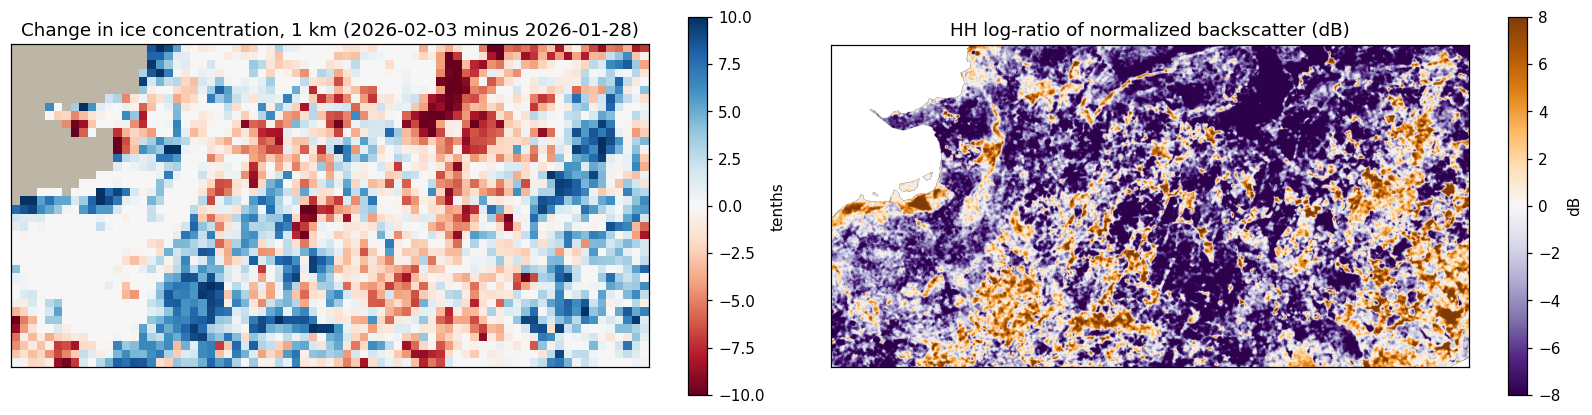

In [16]:
valid_both = (ice_class[0] != 255) & (ice_class[1] != 255)
transition = pd.crosstab(pd.Categorical(ice_class[0][valid_both], categories=range(6)),
                         pd.Categorical(ice_class[1][valid_both], categories=range(6)),
                         normalize="all", dropna=False) * 100
transition.index = [f"{DATES[0]}: {n}" for n in CLASS_NAMES]
transition.columns = [n for n in CLASS_NAMES]
d_ct1 = ct1[1] - ct1[0]
gained = (~ice[0] & ice[1])[ocean].mean()
lost = (ice[0] & ~ice[1])[ocean].mean()
print(f"Ice gained on {gained:.1%} and lost on {lost:.1%} of ocean pixels; mean change in concentration "
      f"{np.nanmean(d_ct1):+.2f} tenths")
display(transition.round(1).style.background_gradient(cmap="Greys", axis=None).format("{:.1f}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
diff_cmap = plt.get_cmap("RdBu").copy()
diff_cmap.set_bad("#bdb5a6")
im = axes[0].imshow(d_ct1, cmap=diff_cmap, vmin=-10, vmax=10, interpolation="nearest")
axes[0].set(title=f"Change in ice concentration, 1 km ({DATES[1]} minus {DATES[0]})", xticks=[], yticks=[])
plt.colorbar(im, ax=axes[0], shrink=0.8, label="tenths")
im = axes[1].imshow(np.where(ocean, dhh, np.nan), cmap="PuOr_r", vmin=-8, vmax=8, extent=extent)
axes[1].set(title="HH log-ratio of normalized backscatter (dB)", xticks=[], yticks=[])
plt.colorbar(im, ax=axes[1], shrink=0.8, label="dB")
plt.tight_layout()
plt.show()

## Ice-cost surface and least-cost route

Each pixel gets a navigation cost from its regime, scaled by the local 1 km ice concentration: `cost = base_cost(class) x (1 + CT / 10)`. Land and the coastal fringe are impassable. The base costs below are illustrative for a ferry or cargo ship with a modest ice class; an icebreaker or a Polar Class vessel would use flatter costs, and a pressure penalty can be added along the south shore when northwest winds are compressing the ice.

| Regime | Base cost |
|---|---|
| Open water | 1 |
| Smooth dark ice | 2 |
| Grey ice | 4 |
| Thin first-year ice | 8 |
| Rough/deformed ice | 15 |
| Landfast candidate | 50 (avoid) |

`skimage.graph.route_through_array` then finds the cheapest 8-connected path between a start point off Baie-Comeau and an end point off Matane. Both points are snapped to the nearest ocean pixel inside the AOI, and the route is compared with the straight line to measure the detour caused by ice.


In [17]:
BASE_COST = np.array([1, 2, 4, 8, 15, 50], "float32")
START_LONLAT, END_LONLAT = (-68.10, 49.20), (-67.55, 48.93)     # off Baie-Comeau, off Matane
to_utm = Transformer.from_crs(4326, CRS, always_xy=True)
to_ll = Transformer.from_crs(CRS, 4326, always_xy=True)
_, (near_r, near_c) = ndi.distance_transform_edt(~ocean, return_indices=True)


def snap(lon, lat):
    col, row = ~transform * to_utm.transform(lon, lat)
    r = int(np.clip(row, 0, grid.shape[0] - 1))
    c = int(np.clip(col, 0, grid.shape[1] - 1))
    return int(near_r[r, c]), int(near_c[r, c])


def rc_to_lonlat(rows_, cols_):
    x, y = transform * (np.asarray(cols_) + 0.5, np.asarray(rows_) + 0.5)
    return to_ll.transform(x, y)


start, end = snap(*START_LONLAT), snap(*END_LONLAT)
routes, route_rows, costs = {}, [], []
for t, d in enumerate(DATES):
    ct_full = np.kron(np.nan_to_num(ct1[t]), np.ones((F1, F1)))
    ct_full = np.pad(ct_full, ((0, grid.shape[0] - ct_full.shape[0]), (0, grid.shape[1] - ct_full.shape[1])), mode="edge")
    cost = np.full(grid.shape, 1e6, "float32")
    ok = ice_class[t] != 255
    cost[ok] = BASE_COST[ice_class[t][ok]] * (1 + ct_full[ok] / 10)
    costs.append(cost)
    path, total = route_through_array(cost, start, end, fully_connected=True, geometric=True)
    r_, c_ = np.array(path).T
    lon, lat = rc_to_lonlat(r_, c_)
    routes[d] = LineString(zip(lon, lat))
    crossed = pd.Series(ice_class[t][r_, c_]).map(dict(enumerate(CLASS_NAMES))).value_counts(normalize=True)
    straight = np.hypot(start[0] - end[0], start[1] - end[1]) * RES / 1000
    length = (np.hypot(np.diff(r_), np.diff(c_)).sum()) * RES / 1000
    route_rows.append({"date": d, "route length (km)": round(length, 1), "straight line (km)": round(straight, 1),
                       "detour": f"{length / straight - 1:.1%}", "total cost": round(float(total), 0),
                       **{f"% {k}": round(100 * v, 1) for k, v in crossed.items()}})
route_table = pd.DataFrame(route_rows).fillna(0)
route_table

,date,route length (km),straight line (km),detour,total cost,% Open water,% Grey ice,% Thin first-year ice,% Smooth dark ice,% Rough/deformed ice
0,2026-01-28,62.7,50.2,25.1%,2822.0,86.1,8.5,2.9,2.4,0.2
1,2026-02-03,67.5,50.2,34.6%,1904.0,93.4,0.3,0.0,6.1,0.2


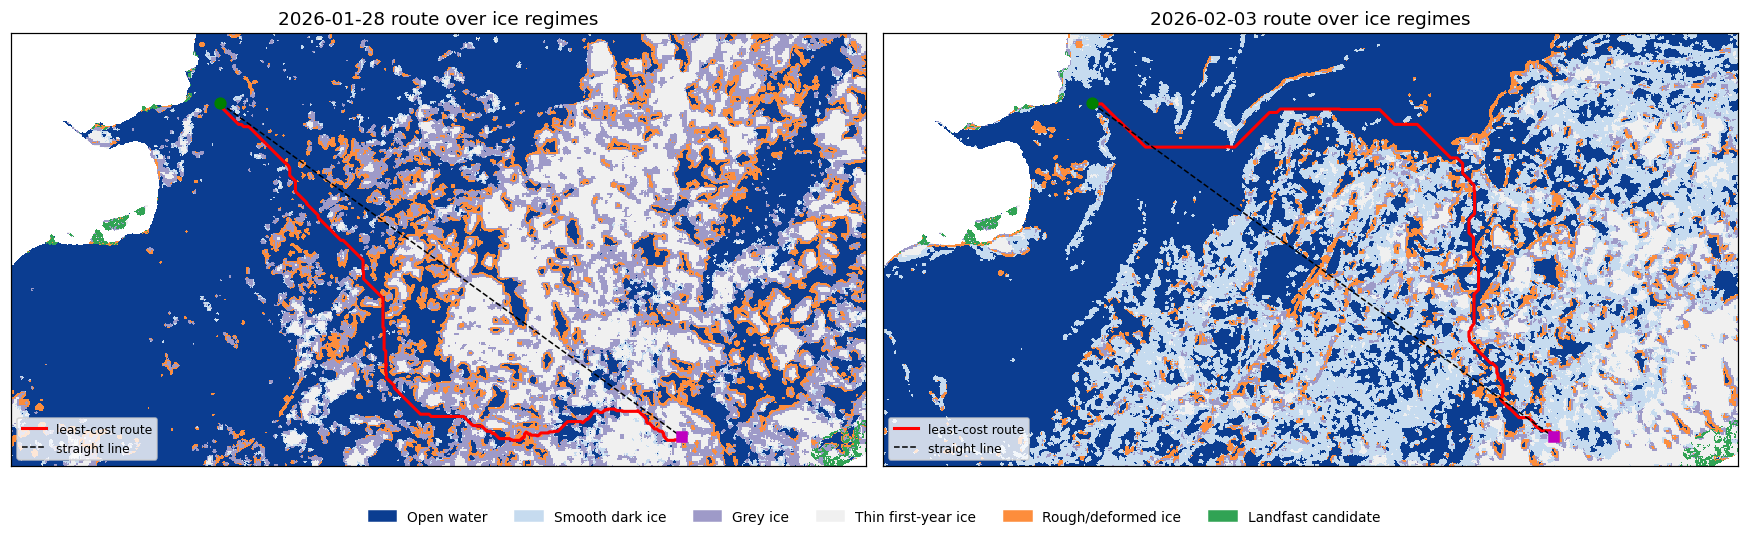

In [18]:
fig, axes = plt.subplots(1, len(DATES), figsize=(16, 4.8))
for t, (d, ax) in enumerate(zip(DATES, axes)):
    show = np.where(ice_class[t] == 255, np.nan, ice_class[t]).astype(float)
    ax.imshow(show, cmap=cmap_cls, norm=norm_cls, interpolation="nearest")
    x, y = to_utm.transform(*np.array(routes[d].coords).T)
    cols_, rows_ = ~transform * (np.asarray(x), np.asarray(y))
    ax.plot(cols_ - 0.5, rows_ - 0.5, color="red", lw=2, label="least-cost route")
    ax.plot([start[1], end[1]], [start[0], end[0]], "k--", lw=1, label="straight line")
    ax.plot(*start[::-1], "go", ms=7)
    ax.plot(*end[::-1], "ms", ms=7)
    ax.set(title=f"{d} route over ice regimes", xticks=[], yticks=[])
    ax.legend(loc="lower left", fontsize=8)
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=6, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

## View routes and ice concentration on satellite imagery

This interactive map overlays the AOI, the 1 km ice concentration of both dates (cells shaded from dark blue for open water to white for full ice cover) and the least-cost routes for both dates on Esri World Imagery. Use the layer control (top right) to switch dates on and off, and hover over a cell or a route to read its values. The map is built with folium, so it is saved in the notebook as HTML and displays in Jupyter, JupyterLab, VS Code and nbviewer without a live widget kernel. Satellite tiles need an internet connection; the basemap is a recent cloud-free mosaic, not imagery from the acquisition dates.


In [19]:
import folium
from matplotlib.colors import to_hex


def concentration_cells(ct):
    rows_ = []
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            if np.isfinite(ct[i, j]):
                x0, y0 = transform * (j * F1, i * F1)
                x1, y1 = transform * ((j + 1) * F1, (i + 1) * F1)
                rows_.append({"ice_tenths": round(float(ct[i, j]), 1), "geometry": box(x0, y1, x1, y0)})
    return gpd.GeoDataFrame(rows_, crs=CRS).to_crs("EPSG:4326")


route_gdf = gpd.GeoDataFrame(
    {"date": list(routes), "length_km": route_table["route length (km)"].values,
     "detour": route_table["detour"].values, "total_cost": route_table["total cost"].values},
    geometry=list(routes.values()), crs="EPSG:4326")

ice_map = folium.Map(location=[(AOI[1] + AOI[3]) / 2, (AOI[0] + AOI[2]) / 2], zoom_start=9, tiles=None,
                     control_scale=True)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Esri World Imagery").add_to(ice_map)

ct_colormap = plt.get_cmap("Blues_r")
for t, d in enumerate(DATES):
    cells = concentration_cells(ct1[t])
    folium.GeoJson(
        cells.to_json(), name=f"Ice concentration {d} (1 km)", show=(t == len(DATES) - 1),
        style_function=lambda f: {"fillColor": to_hex(ct_colormap(f["properties"]["ice_tenths"] / 10)),
                                  "color": "none", "weight": 0, "fillOpacity": 0.6},
        tooltip=folium.GeoJsonTooltip(fields=["ice_tenths"], aliases=[f"Ice {d} (tenths)"]),
    ).add_to(ice_map)

folium.GeoJson(aoi.to_json(), name="AOI",
               style_function=lambda f: {"color": "#00ffff", "weight": 2, "fill": False}).add_to(ice_map)
for d, color in zip(DATES, ["#ff3030", "#ffd700"]):
    folium.GeoJson(
        route_gdf[route_gdf.date == d].to_json(), name=f"Least-cost route {d}",
        style_function=lambda f, c=color: {"color": c, "weight": 4},
        tooltip=folium.GeoJsonTooltip(fields=["date", "length_km", "detour", "total_cost"],
                                      aliases=["Date", "Length (km)", "Detour", "Total cost"]),
    ).add_to(ice_map)
for name, (lon, lat) in {"Baie-Comeau": START_LONLAT, "Matane": END_LONLAT}.items():
    folium.Marker([lat, lon], tooltip=f"Route end point off {name}").add_to(ice_map)
folium.LayerControl(collapsed=False).add_to(ice_map)
ice_map.fit_bounds([[AOI[1], AOI[0]], [AOI[3], AOI[2]]])
ice_map

## Save the outputs

All rasters are written on the common 50 m UTM 19N grid (concentration on its 1 km and 5 km block grids), the routes as GeoJSON, and the tables as CSV, in `outputs/sea_ice_rcm` next to the other capstone outputs.


In [20]:
def to_tif(array, name, factor=1, dtype="float32", nodata=np.nan):
    da = grid.copy(data=np.asarray(array, dtype=dtype)) if factor == 1 else None
    if da is None:
        import xarray as xr
        t_ = transform * Affine.scale(factor)
        ys = t_.f + t_.e * (np.arange(array.shape[0]) + 0.5)
        xs = t_.c + t_.a * (np.arange(array.shape[1]) + 0.5)
        da = xr.DataArray(np.asarray(array, dtype=dtype), dims=("y", "x"), coords={"y": ys, "x": xs})
        da = da.rio.write_crs(CRS).rio.write_transform(t_)
    da.rio.write_nodata(nodata).rio.to_raster(OUT_DIR / name)
    return name


written = []
for t, d in enumerate(DATES):
    written += [to_tif(hh_n.isel(time=t).values, f"{d}_HH_norm{int(REF_DEG)}_db.tif"),
                to_tif(hv_db.isel(time=t).values, f"{d}_HV_db.tif"),
                to_tif(np.where(ocean, ice[t], 255), f"{d}_ice_water.tif", dtype="uint8", nodata=255),
                to_tif(ice_class[t], f"{d}_ice_regimes.tif", dtype="uint8", nodata=255),
                to_tif(ct1[t], f"{d}_ice_concentration_1km.tif", factor=F1),
                to_tif(ct5[t], f"{d}_ice_concentration_5km.tif", factor=F5),
                to_tif(np.where(costs[t] >= 1e6, np.nan, costs[t]), f"{d}_ice_cost.tif")]
written += [to_tif(np.where(ocean, dhh, np.nan), "HH_change_db.tif"),
            to_tif(d_ct1, "ice_concentration_change_1km.tif", factor=F1)]
route_gdf.to_file(OUT_DIR / "least_cost_routes.geojson", driver="GeoJSON")
route_table.to_csv(OUT_DIR / "route_summary.csv", index=False)
summary.to_csv(OUT_DIR / "ice_regime_area_km2.csv")
transition.round(3).to_csv(OUT_DIR / "regime_transition_percent.csv")
fits.to_csv(OUT_DIR / "incidence_slope_fits.csv", index=False)
written += ["least_cost_routes.geojson", "route_summary.csv", "ice_regime_area_km2.csv",
            "regime_transition_percent.csv", "incidence_slope_fits.csv"]
print(f"{len(written)} files in {OUT_DIR}:", *written, sep="\n  ")

21 files in outputs/sea_ice_rcm:
  2026-01-28_HH_norm35_db.tif
  2026-01-28_HV_db.tif
  2026-01-28_ice_water.tif
  2026-01-28_ice_regimes.tif
  2026-01-28_ice_concentration_1km.tif
  2026-01-28_ice_concentration_5km.tif
  2026-01-28_ice_cost.tif
  2026-02-03_HH_norm35_db.tif
  2026-02-03_HV_db.tif
  2026-02-03_ice_water.tif
  2026-02-03_ice_regimes.tif
  2026-02-03_ice_concentration_1km.tif
  2026-02-03_ice_concentration_5km.tif
  2026-02-03_ice_cost.tif
  HH_change_db.tif
  ice_concentration_change_1km.tif
  least_cost_routes.geojson
  route_summary.csv
  ice_regime_area_km2.csv
  regime_transition_percent.csv
  incidence_slope_fits.csv


## Review, validation, and limitations

**Validate before use.** Download the CIS Gulf of St. Lawrence charts (SIGRID-3 shapefiles) for 28 January and 3 February 2026 or the nearest dates. Compare the 5 km concentration with the chart total concentration (`CT`) and report bias, RMSE and R². To replace the unsupervised regimes with a supervised classifier, rasterize chart polygons where one stage of development dominates (partial concentration of 8/10 or more) onto the common grid, refine them by visual interpretation of the SAR images, sample a balanced set of pixels per class from the Section 7 feature stack, and train a `sklearn.ensemble.RandomForestClassifier`; train on 28 January and test on 3 February to check transfer across beams. Route results can be checked against AIS tracks for the same days: measure how far real ship tracks are from the modelled route and which regimes ships actually crossed (`sar.ship.match_points` handles the point matching).

**Limitations.**

- *Resolution*: 100 m resolution cannot resolve narrow leads, small floes or individual ridges; ridges appear only as texture.
- *Wind*: wind-roughened open water can be mistaken for ice, especially in HH. Pixels are flagged, not removed, because no wind data are bundled.
- *Young ice*: new, grey and grey-white ice have similar backscatter, so confusion between regimes 1 to 3 is expected.
- *Different beams*: SCLNA and SCLND have different incidence angles and noise profiles; normalization reduces but does not remove the difference.
- *Noise floor*: at the 50 to 54 degree incidence of the 3 February scene, HV over most of the AOI is within about a decibel of the NESZ, so that date is mapped from HH alone and wind-roughened water cannot be tested on it. Prefer acquisitions at moderate incidence (below about 40 degrees) when HV matters.
- *Incidence normalization*: a single linear slope is an approximation over a 17 degree difference between the dates; open water and different ice types have different slopes, so residual differences between dates remain.
- *Geocoding*: ellipsoid tie-point geocoding is accurate over water but can be off by a pixel or two on steep coast; the coastal buffer hides this.
- *Land mask*: Natural Earth 1:10m is generalized; small islands, piers and narrow bays may be misclassified.
- *Time gap*: 6 days is too long for ice drift tracking in the estuary; changes are net state changes.
- *Unsupervised regimes*: cluster names are interpretations and cluster boundaries depend on the ice present on these two dates.


## Summary and conclusions

This notebook processes two RCM ScanSAR Low Noise GRD scenes end to end with GeoLattice and no external SAR software. `rcm.read_rcm_grd_subset` reads only the AOI window of each scene, calibrates it to sigma-nought with the product's gain tables, removes the ScanSAR noise floor and returns ground control points and incidence angles; refined Lee filtering with a measured ENL, geocoding of both dates onto one UTM grid, a land and coastal mask, and incidence normalization with a slope fitted from the data make the two beams comparable. On that common basis the notebook separates ice from open water, groups ice into regimes with texture, computes ice concentration in tenths at 1 km and 5 km, measures net change between 28 January and 3 February, and turns the ice maps into an ice-cost surface and a least-cost route between Baie-Comeau and Matane. The outputs are saved as GeoTIFF, GeoJSON and CSV.

**Results for these two scenes.** About half of the open estuary inside the AOI was ice-covered on both dates (49.9% of ocean pixels on 28 January and 52.2% on 3 February; mean concentration 5.0 and 5.2 tenths on the 1 km grid), with open water along the north shore off Baie-Comeau and in the west, and denser ice toward the south and east. The total hardly changed, but the ice moved: 18.5% of ocean pixels gained ice and 16.3% lost it between the dates. On 28 January HV stood about 4 dB above the noise floor and agreed with the HH ice map on 88.8% of pixels; on 3 February, at 50 to 54 degrees incidence, HV was at the noise floor and the map relies on HH alone. The least-cost crossing from off Baie-Comeau to off Matane was 62.7 km on 28 January (25% longer than the straight line, 86% in open water) and 67.5 km on 3 February (35% longer, 93% in open water), the second route swinging north through the open lead along the north shore. The large rise in "smooth dark ice" on 3 February should be read with caution: part of it is the steeper viewing geometry, which darkens ice more than the single normalization slope corrects, rather than new ice formation.

The ice/water split and the route are the most robust products. The ice regimes and landfast candidates are interpretations of unsupervised clusters and should be checked against CIS charts, and wind-roughened water should be reviewed with wind data, before the maps are used for navigation. The same workflow extends naturally to a winter time series, to scenes one or two days apart for drift tracking, and to a supervised classifier once chart labels are available.


## Additional resources

- [Canadian Space Agency: RADARSAT Constellation Mission](https://www.asc-csa.gc.ca/eng/satellites/radarsat/)
- [EODMS, the Earth Observation Data Management System (RCM data access)](https://www.eodms-sgdot.nrcan-rncan.gc.ca/)
- [Canadian Ice Service ice charts and archive](https://www.canada.ca/en/environment-climate-change/services/ice-forecasts-observations.html)
- [WMO Sea-Ice Nomenclature (WMO-No. 259)](https://library.wmo.int/idurl/4/41953)
- [Natural Earth land data](https://www.naturalearthdata.com/)
- [Written workflow for this capstone](https://github.com/zia207/GeoLattice/blob/main/docs/sea_ice_mapping_rcm_aoi.md)
- [GeoLattice RADARSAT module](https://github.com/zia207/GeoLattice/blob/main/src/rsense/sar/radarsat.py)
- [GeoLattice Sentinel-1 and generic SAR processing module](https://github.com/zia207/GeoLattice/blob/main/src/rsense/sar/sentinel1.py)
- [GeoLattice texture module](https://github.com/zia207/GeoLattice/blob/main/src/rsense/texture.py)

RCM data are distributed by the Government of Canada under the RCM public end-user licence included in each product folder (`RCM_EULA_PUBLIC_v1-0_20191213_UNCLASSIFIED.pdf`).
